In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random
from scipy.stats import norm

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder as skTE
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')
pd.set_option("display.max_columns", 100)
# sns.set_style("whitegrid")

In [4]:
!uv pip install -q -U bartz

In [5]:
from bartz.BART import gbart, mc_gbart

!pip show bartz

Name: bartz
Version: 0.14.0
Summary: Super-fast BART (Bayesian Additive Regression Trees) in Python
Home-page: https://github.com/bartz-org/bartz
Author: 
Author-email: Giacomo Petrillo <info@giacomopetrillo.com>
License-Expression: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: equinox, jax, jaxtyping, numpy, scipy, tqdm, typing-extensions
Required-by: 


In [6]:
!uv pip install -q bartz[cuda13]

In [7]:
## -- Tell JAX to use all and only 95% of the GPU memory
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = '.95'

print("📥 Memory limited to 95% usage")

📥 Memory limited to 95% usage


In [8]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [9]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [10]:
%%time

ID = 'id'
TARGET = 'is_fraud'

# X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
# y = train[TARGET]
# X_test = test.drop([ID], axis=1); test_id = test[ID]

# print('-'*40)
# print("X      init shape:", X.shape)
# print("X_test init shape:", X_test.shape, "\n")

cat_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = train.drop([ID, TARGET], axis=1).select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols

float_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['float']).columns.tolist()
int_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['int']).columns.tolist()
obj_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()

print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols))
print("init len(float_cols):", len(float_cols))
print("init len(int_cols):", len(int_cols))
print("init len(object_cols):", len(obj_cols))
print("init len(total cols):", len(base_cols), '\n')

init len(cat_cols): 11
init len(num_cols): 13
init len(float_cols): 6
init len(int_cols): 7
init len(object_cols): 11
init len(total cols): 24 

CPU times: user 398 ms, sys: 55.8 ms, total: 454 ms
Wall time: 527 ms


In [11]:
# # import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(test[base_cols], index=False)

# # Find rows where they don't match
# mismatches = hash1 != hash2
# # print("Rows that changed:", mismatches)

In [12]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

,0
is_new_merchant,2
is_fraud,2
is_ai_generated_scam_attempt,2
billing_shipping_mismatch,2
ip_country_mismatch,2
used_vpn,2
is_foreign_transaction,2
cvv_retry_count,4
auth_method,5
prior_disputes,5


In [13]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_trn, y_trn = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_trn.copy()
            temp_df_train['target'] = y_trn

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_trn.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [14]:
## -- original_TE with factorization --

from typing import List, Optional, Tuple

def original_fcTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies out-of-fold / external dataset target encoding (TE) from `orig` onto `df`.
    """
    X_df = df.copy()
    orig_df = orig.copy()  # Prevent mutating the caller's original DataFrame

    # 1. Early exit with consistent return signature (DataFrame, list)
    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig_df.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    # 2. Validate features exist in BOTH DataFrames
    valid_features = [
        col for col in features
        if col in orig_df.columns and col in X_df.columns
    ]

    # Separate 'count' from target-dependent aggregations
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Align categorical/object/bool dtypes safely only for needed columns
        if pd.api.types.is_object_dtype(X_df[col]) or \
           isinstance(X_df[col].dtype, pd.CategoricalDtype) or \
           pd.api.types.is_bool_dtype(X_df[col]):
            combined = pd.concat([X_df[col], orig_df[col]], ignore_index=True)
            codes, _ = pd.factorize(combined, sort=True)
            X_df[col] = codes[:len(X_df)]
            orig_df[col] = codes[len(X_df):]

        # Group once per feature instead of once per (feature, agg)
        grouped = orig_df.groupby(col, dropna=False)

        # Compute target aggregations in one vectorized pass
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # .map() preserves X_df's exact index and row order
                    new_features_dict[new_col] = X_df[col].map(agg_stats[agg_key])
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        # Handle 'count' separately since it doesn't depend on `target`
        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts = grouped.size()
            new_features_dict[new_col] = X_df[col].map(counts)
            orig_cols.append(new_col)

    # Concatenate all new columns at once to avoid DataFrame fragmentation
    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    # 3. Fill missing values cleanly
    if fill_nan and orig_cols:
        global_mean = orig_df[target].mean()
        global_median = orig_df[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Factorized augment function ready! --')

-- Factorized augment function ready! --


In [15]:
## -- original_TE with objects --

from typing import List, Optional, Tuple

def original_obTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies external dataset target encoding (TE) from `orig` onto `df`
    while preserving original categorical/string dtypes.
    """
    X_df = df.copy()

    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    valid_features = [
        col for col in features
        if col in orig.columns and col in X_df.columns
    ]

    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Group directly on raw strings, objects, or categories (observed=True prevents cartesian blowups)
        grouped = orig.groupby(col, dropna=False, observed=True)

        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # Convert Series to plain dict so CategoricalIndex mismatches don't cause issues
                    mapping_dict = agg_stats[agg_key].to_dict()
                    new_features_dict[new_col] = X_df[col].map(mapping_dict).astype('float32')
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts_dict = grouped.size().to_dict()
            new_features_dict[new_col] = X_df[col].map(counts_dict).astype('float32')
            orig_cols.append(new_col)

    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    if fill_nan and orig_cols:
        global_mean = orig[target].mean()
        global_median = orig[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Object augment function ready! --')

-- Object augment function ready! --


## FEATURE ENGINEERING

In [16]:
# ## -- Cyclic encoding --

# for df in [train, test]:
#     for p in [8, 12, 24]:
#         df[f"sleep_hours_sin_{p}"] = np.sin(2 * np.pi * df["sleep_hours"] / p).astype("float32")
#         df[f"sleep_hours_cos_{p}"] = np.cos(2 * np.pi * df["sleep_hours"] / p).astype("float32")

In [17]:
## -- Numeric to Categorical (TargetEncoding) -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test], ignore_index=True)
## ------------------------------------------------------------
# -- Duplicate Nums as Cats --
nums_to_cats = []

select_nc = num_cols
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_CAT_"
    combined[new_cat], unique = pd.factorize(combined[c], sort=True)
    combined[new_cat] = combined[new_cat].astype('int32') #.astype('category')
    nums_to_cats.append(new_cat)
## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", train.shape[1])

Features before operation: 24


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

Features after operation: 39


In [18]:
## -- Frequency encoding -- ⚠️
freq_cols = []
combined = pd.concat([train, test], ignore_index=True)

select_freq = num_cols
print("\nCreating frequencies (Safe Global Mapping)...")
for col in select_freq:
    n = f"{col}_FREQ_"
    # print(f"⧗ {n}", end="")

    # Calculate frequencies using ONLY train
    freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

    # Map the training-derived frequencies across all datasets safely
    train[n] = train[col].map(freq_map).fillna(0).astype("float32")
    test[n] = test[col].map(freq_map).fillna(0).astype("float32")
    # orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

    freq_cols.append(n)
    # print()

print(f"\n *** Total frequency features: {len(freq_cols)}")
train[freq_cols].nunique()


Creating frequencies (Safe Global Mapping)...

 *** Total frequency features: 13


,0
amount_usd_FREQ_,582
hours_since_last_txn_FREQ_,790
txn_count_last_24h_FREQ_,12
distance_from_home_km_FREQ_,741
card_age_months_FREQ_,49
customer_age_FREQ_,63
account_balance_usd_FREQ_,404
cvv_retry_count_FREQ_,4
velocity_score_FREQ_,499
time_of_day_hour_FREQ_,24


In [19]:
# ## -- Groupby features FE -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Total features before operation:", len(FEATURES))

# combined = pd.concat([train, test, orig])
# ## ------------------------------------------------------------------------
# # for c in tqdm(cat_cols, desc="factorize_cats"):
# #     combined[c] = (pd.factorize(combined[c])[0]).astype('int32')

# ## ------------------------------------------------------------------------
# GROUP_COLS = []
# grouper  = 'Flight Distance'
# agg_cols = ['Class', 'Type of Travel'] + service_cols

# for col in agg_cols:
#     g_col = f"{col}_{grouper.split(' ')[0]}_GROUPBY".replace(" ", "")
#     combined[f"{g_col}_mean"] = combined.groupby([grouper])[col].transform('mean')
#     # combined[f"{g_col}_std"] = combined.groupby([grouper])[col].transform('std')
#     # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
#     GROUP_COLS.append(g_col)

# # for col in service_cols + ['Class', 'Type of Travel']:
# #     g_col = f"{col}_AGE_GROUPBY".replace(" ", "")
# #     combined[f"{g_col}_mean"] = combined.groupby(['Age'])[col].transform('mean')
#     # combined[f"{g_col}_std"] = combined.groupby(['Age'])[col].transform('std')
#     # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
#     # groupers.append(g_col)

# # FEATURES = list(set(FEATURES + GROUP_COLS))
# ## ------------------------------------------------------------------------

# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Total features after operation:", len(FEATURES))

In [20]:
# ## -- DIGITS extraction -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

# combined = pd.concat([train, test, orig], ignore_index=True)
# digit_cols = []

# for col in num_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') #.astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig = combined.iloc[-len(orig):]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [21]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)

print(train.shape, test.shape)
train[digit_cols2].nunique()

(699960, 88) (299984, 87)


,0
amount_usd__int,1144
amount_usd__int10,235
amount_usd__tenths,4599
amount_usd__cents,100
amount_usd__lead1,33
amount_usd__lead2,217
hours_since_last_txn__int,51
hours_since_last_txn__int10,6
hours_since_last_txn__tenths,502
hours_since_last_txn__cents,100


In [22]:
# ## Floor//Binning feature -- ⚠️
# floor_cols = []

# combined = pd.concat([train, test, orig])

# # for f in tqdm([1000], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Flight Distance']:
# #         f_name = f"{c}_flr{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
# #         # combined[f_name] = (combined[c].fillna(0) // f).astype('int32').astype('category')
# #         floor_cols.append(f_name)
# #         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# for f in tqdm([5], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Age']:
#         age_n = f"{c}_flr{f}"
#         print(f" ⧗ {age_n}", end='... ')
#         combined[age_n] = (combined[c] // f).astype('int32')
#         floor_cols.append(age_n)
#         print()

# # combined[f"age{f}_X_dist1000"] = combined[age_n] * combined[f_name]

# # FEATURES = list(set(FEATURES + floor_cols))

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

# ML TRAINING

In [23]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=50_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

print(f"Train shape {train_X.shape}")
# train_X.head()

(699960, 88) <class 'pandas.core.frame.DataFrame'>
Train shape (699960, 88)


In [24]:
## -- Handle optional original table aggregations
USE_ORIGINAL = True

import_cols = base_cols

if USE_ORIGINAL:
    aggs_ = ["count"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_obTE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_obTE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int8")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int8")

print(X.shape, type(X))
X.head()

original_augmenting:   0%|          | 0/24 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/24 [00:00<?, ?it/s]

(699960, 110) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_,amount_usd_FREQ_,hours_since_last_txn_FREQ_,txn_count_last_24h_FREQ_,distance_from_home_km_FREQ_,card_age_months_FREQ_,customer_age_FREQ_,account_balance_usd_FREQ_,cvv_retry_count_FREQ_,velocity_score_FREQ_,time_of_day_hour_FREQ_,day_of_week_FREQ_,merchant_risk_score_FREQ_,prior_disputes_FREQ_,...,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,oTE_merchant_category_count,oTE_card_type_count,oTE_auth_method_count,oTE_channel_count,oTE_device_type_count,oTE_is_foreign_transaction_count,oTE_is_new_merchant_count,oTE_used_vpn_count,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_count,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_count,oTE_card_age_months_count,oTE_customer_age_count,oTE_account_balance_usd_count,oTE_cvv_retry_count_count,oTE_velocity_score_count,oTE_time_of_day_hour_count,oTE_day_of_week_count,oTE_merchant_risk_score_count,oTE_prior_disputes_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0,9.0,236.0,92705.0,494.0,50401.0,13017.0,42.0,642088.0,1089.0,30978.0,97261.0,2181.0,598396.0,...,19,109,17,1,177,78,21,217,1269,126,12693,35,41,412,5,0,55,50,15,105,29,2,292,20,22,229,3242.0,6629.0,4792.0,5191.0,4179.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,2.0,7.0,2692.0,9.0,1172.0,315.0,1.0,16658.0,38.0,845.0,2810.0,48.0,15085.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1,262.0,1425.0,178367.0,28.0,13426.0,11020.0,205.0,642088.0,1189.0,28247.0,95271.0,2059.0,96365.0,...,11,101,13,1,130,6,21,213,3233,323,32330,0,43,432,33,3,334,40,23,233,29,2,299,90,22,229,3416.0,8417.0,4173.0,3225.0,5503.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,4.0,22.0,4406.0,3.0,488.0,311.0,1.0,16658.0,36.0,809.0,2775.0,50.0,4271.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0,173.0,229.0,131869.0,385.0,40158.0,14624.0,36.0,642088.0,848.0,32922.0,100548.0,1127.0,598396.0,...,11,101,8,0,81,17,18,108,1046,104,10468,88,41,410,35,3,358,80,23,235,24,2,241,10,22,224,1330.0,8417.0,4792.0,6810.0,1161.0,18760.0,15399.0,1759.0,18834.0,19127.0,19625.0,1.0,20.0,3569.0,7.0,1030.0,331.0,1.0,16658.0,25.0,876.0,2849.0,24.0,15085.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,3098,511,4,840,24

In [25]:
# pd.concat([X[groupers+INTER], y], axis=1).corr()

In [26]:
# corr_type = ['pearson', 'spearman'][0]

# plt.figure(figsize=(15, 4))
# corr_df = X.corrwith(train_X[TARGET], method=corr_type)
# corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
# for i, v in enumerate(corr_df.values):
#     plt.text(
#         i, np.abs(v) + 0.001, np.round(v, 3),
#         size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
#         va='bottom', ha='center',
#     )

# plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
# plt.show()

In [27]:
## -- Reduce data memory --

def reduce_memory(df, factorize_first=False):
    # Use copy() if you want to avoid modifying the original dataframe in place
    # df = df.copy()

    old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

    for c in tqdm(df.columns, desc='Reducing memory...'):
        col_type = df[c].dtype
        # Check if type is bool (True or False)
        if col_type == bool:
            if factorize_first:
                df[c], _ = df[c].factorize(sort=True)
                df[c] = df[c].astype('category')
            else:
                df[c] = df[c].astype(str).astype('category')
        # Check if type is integer
        elif np.issubdtype(col_type, np.integer):
            df[c] = pd.to_numeric(df[c], downcast='integer')
        # Optional: Convert object types with low cardinality to category
        elif col_type == object or col_type.name == 'category':
            if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
                if factorize_first:
                    df[c], _ = df[c].factorize(sort=True)
                    df[c] = df[c].astype('category')
                else:
                    df[c] = df[c].astype('category')
        # Check if type is float
        # elif np.issubdtype(col_type, np.floating):
        #     df[c] = pd.to_numeric(df[c], downcast='float')

    new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

    return df

X = reduce_memory(X, factorize_first=True)
X_test = reduce_memory(X_test, factorize_first=True)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

X.head()

Reducing memory...:   0%|          | 0/110 [00:00<?, ?it/s]

Size before process: 588.6 MB
Size after process : 195.6 MB



Reducing memory...:   0%|          | 0/110 [00:00<?, ?it/s]

Size before process: 252.2 MB
Size after process : 83.8 MB

Data memory reduced!


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_,amount_usd_FREQ_,hours_since_last_txn_FREQ_,txn_count_last_24h_FREQ_,distance_from_home_km_FREQ_,card_age_months_FREQ_,customer_age_FREQ_,account_balance_usd_FREQ_,cvv_retry_count_FREQ_,velocity_score_FREQ_,time_of_day_hour_FREQ_,day_of_week_FREQ_,merchant_risk_score_FREQ_,prior_disputes_FREQ_,...,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,oTE_merchant_category_count,oTE_card_type_count,oTE_auth_method_count,oTE_channel_count,oTE_device_type_count,oTE_is_foreign_transaction_count,oTE_is_new_merchant_count,oTE_used_vpn_count,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_count,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_count,oTE_card_age_months_count,oTE_customer_age_count,oTE_account_balance_usd_count,oTE_cvv_retry_count_count,oTE_velocity_score_count,oTE_time_of_day_hour_count,oTE_day_of_week_count,oTE_merchant_risk_score_count,oTE_prior_disputes_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,4829,970,1,1668,24,38,19600,0,55,17,3,276,0,9.0,236.0,92705.0,494.0,50401.0,13017.0,42.0,642088.0,1089.0,30978.0,97261.0,2181.0,598396.0,...,19,109,17,1,177,78,21,217,1269,126,12693,35,41,412,5,0,55,50,15,105,29,2,292,20,22,229,3242.0,6629.0,4792.0,5191.0,4179.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,2.0,7.0,2692.0,9.0,1172.0,315.0,1.0,16658.0,38.0,845.0,2810.0,48.0,15085.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,2071,153,3,1236,14,10,40403,0,335,23,5,283,1,262.0,1425.0,178367.0,28.0,13426.0,11020.0,205.0,642088.0,1189.0,28247.0,95271.0,2059.0,96365.0,...,11,101,13,1,130,6,21,213,3233,323,32330,0,43,432,33,3,334,40,23,233,29,2,299,90,22,229,3416.0,8417.0,4173.0,3225.0,5503.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,4.0,22.0,4406.0,3.0,488.0,311.0,1.0,16658.0,36.0,809.0,2775.0,50.0,4271.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,412,119,4,790,26,37,14850,0,359,15,0,225,0,173.0,229.0,131869.0,385.0,40158.0,14624.0,36.0,642088.0,848.0,32922.0,100548.0,1127.0,598396.0,...,11,101,8,0,81,17,18,108,1046,104,10468,88,41,410,35,3,358,80,23,235,24,2,241,10,22,224,1330.0,8417.0,4792.0,6810.0,1161.0,18760.0,15399.0,1759.0,18834.0,19127.0,19625.0,1.0,20.0,3569.0,7.0,1030.0,331.0,1.0,16658.0,25.0,876.0,2849.0,24.0,15085.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,3098,511,4,840,24,30,31978,0,207,7,3,403,0,156.0,216.0,131869.0,462.0,50401.0,13652.0,37.0,642088.0,2978.0,29779.0,97261.0,2387.0,598396.0,...,15,105,8,0,86,67,18,108,2217,221,22176,67,42,422,20,2,207,70,22,220,41,4,419,90,24,241,324

In [28]:
# amount_usd_FREQ_train
# 9.0
# 262.0
# 173.0
# 156.0
# 18.0

# amount_usd_FREQ_combined
# 13.0
# 372.0
# 258.0
# 226.0
# 27.0

In [29]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Columns: 110 entries, amount_usd to oTE_prior_disputes_count
dtypes: category(11), float32(37), float64(6), int16(18), int32(4), int8(34)
memory usage: 195.6 MB


In [30]:
# import jax
# # Attempt to resolve StableHLO/JIT serialization issues by disabling JIT compilation
# # or forcing alternate compilation configurations if necessary.
# jax.config.update("jax_disable_jit", True)

class CFG:
    TE = True if 'nums_to_cats' in globals() else False
    PREDICT_TEST = True
    FOLDS = 5
    SEED = 42
    STOP = 50 # 50, 250
    VERB = 100 # 100, 300

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = 'BARTZp'
print(f"🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds\n")

oof_preds  = np.zeros(len(train_X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + digit_cols2
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        smooth = 'auto'
        print(f"⚡️ TargetEncoding({len(te_cols)}) • smooth={smooth}", end=" | ")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ----------------------------------------------------------------
    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    params = {
        "type": 'pbart',
        # 'ntree':  70, # d=50
        'mc_cores': 6, # d=2
        'keepevery': 50, # d=10
        # ------------------------
        # 'k': 4.0, # d=2.0
        # ------------------------
        # #'ndpost': 500, # d=1000
        'nskip': 150, # d=100
        # # 'numcut': 255, # d=100
        # ------------------------
        # # 'usequants': True,
        # #'sparse': True,
        # #'augment':True,
        # "seed": 42, # d=0
    }

    seeder = 42 #+ (fold-1)
    params['seed'] = seeder

    model = mc_gbart(
        X_trn,
        y_trn.astype(bool) if params['type']=="pbart" else y_trn.astype('float32'),
        # x_test=X_tst.to_numpy(),
        **params,
    )

    val_preds = model.predict(X_val).mean(axis=0).ravel()
    # val_preds = norm.cdf(model.predict(X_val).mean(axis=0).ravel())
    oof_preds[val_idx] = val_preds

    if CFG.PREDICT_TEST:
        t_ = time()
        print("⧗ test predictions... ", end="")
        fold_test_preds = model.predict(X_tst).mean(axis=0).ravel()
        # fold_test_preds = norm.cdf(model.predict(X_tst).mean(axis=0).ravel())
        test_preds += fold_test_preds
        print(f"{(time()-t_)/60:.2f} min")
    # ----------------------------------------------------------------------------------
    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model.ndpost
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed= {seeder}, tree= {best_iter}, time= {ff} mins ]\n")

test_preds /= FOLDS
model_name = model_name + f"({X_trn.shape[1]})"
features_used = X_trn.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (score, tree, dura) in enumerate(zip(fold_scores, best_iterations, fold_times), 1):
    print(f" • Fold {i} AUC: {score} @ tree {tree} in {dura} mins")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'tree'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_trn, X_val, y_trn, y_val, model

🚀 Training BARTZp(110) with 5 Folds

### Fold 1/5
⚡️ TargetEncoding(49) • smooth=auto | train=(559968, 110), valid=(139992, 110)



train   0%|          | 0/8500 [00:00<?, ?it/s]

⧗ test predictions... 0.13 min
Fold 1 AUC: 0.94856 [ seed= 42, tree= 1002, time= 3.36 mins ]

### Fold 2/5
⚡️ TargetEncoding(49) • smooth=auto | 

train   0%|          | 0/8500 [00:00<?, ?it/s]

⧗ test predictions... 0.11 min
Fold 2 AUC: 0.94962 [ seed= 42, tree= 1002, time= 3.07 mins ]

### Fold 3/5
⚡️ TargetEncoding(49) • smooth=auto | 

train   0%|          | 0/8500 [00:00<?, ?it/s]

⧗ test predictions... 0.11 min
Fold 3 AUC: 0.95441 [ seed= 42, tree= 1002, time= 3.08 mins ]

### Fold 4/5
⚡️ TargetEncoding(49) • smooth=auto | 

train   0%|          | 0/8500 [00:00<?, ?it/s]

⧗ test predictions... 0.11 min
Fold 4 AUC: 0.95035 [ seed= 42, tree= 1002, time= 3.05 mins ]

### Fold 5/5
⚡️ TargetEncoding(49) • smooth=auto | 

train   0%|          | 0/8500 [00:00<?, ?it/s]

⧗ test predictions... 0.11 min
Fold 5 AUC: 0.94408 [ seed= 42, tree= 1002, time= 3.07 mins ]


5-FOLD CV: BARTZp(110) | (559968, 110)
 • Fold 1 AUC: 0.94856 @ tree 1002 in 3.36 mins
 • Fold 2 AUC: 0.94962 @ tree 1002 in 3.07 mins
 • Fold 3 AUC: 0.95441 @ tree 1002 in 3.08 mins
 • Fold 4 AUC: 0.95035 @ tree 1002 in 3.05 mins
 • Fold 5 AUC: 0.94408 @ tree 1002 in 3.07 mins
--------------------------------------------------
OOF score: 0.94934
AVG score: 0.9494 ± 0.00332
--------------------------------------------------
15.68 mins



In [31]:
# ==================================================
# 5-FOLD CV: BARTZp(110) | (559968, 110)
# ==================================================
#  • Fold 1 AUC: 0.94856 @ tree 1002 in 3.36 mins
#  • Fold 2 AUC: 0.94962 @ tree 1002 in 3.07 mins
#  • Fold 3 AUC: 0.95441 @ tree 1002 in 3.08 mins
#  • Fold 4 AUC: 0.95035 @ tree 1002 in 3.05 mins
#  • Fold 5 AUC: 0.94408 @ tree 1002 in 3.07 mins
# --------------------------------------------------
# OOF score: 0.94934
# AVG score: 0.9494 ± 0.00332
# --------------------------------------------------
# 15.68 mins

In [32]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
BARTZp(110)_9494
-------------------------
15.7 mins



,auc,tree,time(min)
fold 1,0.94856,1002,3.36
fold 2,0.94962,1002,3.07
fold 3,0.95441,1002,3.08
fold 4,0.95035,1002,3.05
fold 5,0.94408,1002,3.07


In [33]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000047
1,699961,0.000005
2,699962,0.087362
3,699963,0.000521
4,699964,0.000372


In [34]:
# !rm -r /kaggle/working

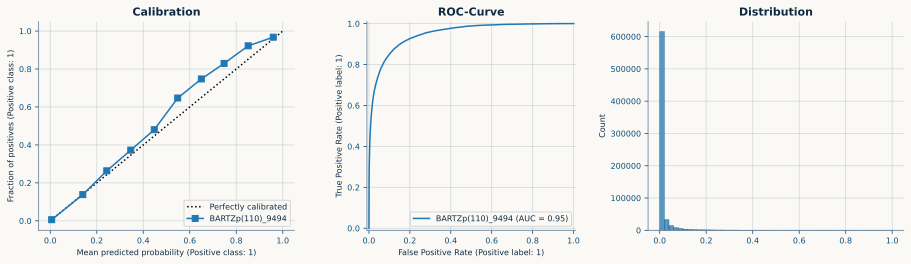

In [35]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 3.5))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout(pad=0.2)
plt.show()

In [ ]:
# ## -- Feature Importances --
# top_n_features = 30

# imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()
# print(f"Total used features: {len(imp_df)}\n")

# ax = imp_df[-top_n_features:].plot.barh(figsize=(12.5, 8))
# ax.set_title(f"{n}: Avg. {FOLDS}-Fold Importances", loc='left')
# ax.grid(True)

# plt.tight_layout()
# plt.show()